# Etapa 2 — Modelos: primeira versão e diagnóstico

**Projeto:** previsão da volatilidade do Ibovespa
**Pergunta:** modelos de machine learning preveem a volatilidade do Ibovespa fora da amostra melhor do que o GARCH(1,1) e o HAR?

Este notebook estima a **primeira versão** dos modelos e faz o diagnóstico inicial. O desenho é propositalmente simples:

- **Divisão fixa.** Os modelos são estimados uma única vez, com os dados de 2000 a 2006 (treino). Depois, preveem de 2007 em diante (teste), sem reestimar. Na Etapa 3, a avaliação passa a usar janela expansiva, com reestimação a cada 22 dias.
- **Mesma unidade para todos.** Todos os modelos preveem a volatilidade anualizada em %, a mesma unidade do alvo.
- **Sem ajuste fino.** Os hiperparâmetros do random forest são fixos e foram definidos antes de ver o teste.
- **Sem teste estatístico.** Esta etapa compara apenas o MSE. O teste de Diebold-Mariano, que diz se uma diferença de erro é estatisticamente significativa, fica para a Etapa 3.

O código dos modelos está em `src/modelos.py`, e este notebook só o executa e mostra os resultados.

In [1]:
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.inspection import permutation_importance
from statsmodels.stats.diagnostic import acorr_ljungbox
from statsmodels.tsa.stattools import acf

RAIZ = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
sys.path.insert(0, str(RAIZ / "src"))
import features as F  # noqa: E402
import modelos as M  # noqa: E402

PASTA_FIG = RAIZ / "figuras"
PASTA_FIG.mkdir(exist_ok=True)
ESTRESSE = {"2008": ("2008-01-01", "2008-12-31"),
            "2015–2016": ("2015-01-01", "2016-12-31"),
            "2020": ("2020-01-01", "2020-12-31")}

AZUL, LARANJA, VERDE, CINZA, SOMBRA = "#2a78d6", "#eb6834", "#1baf7a", "#52514e", "#e6e5e1"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 200, "figure.facecolor": "white",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.6,
    "axes.edgecolor": CINZA, "xtick.color": CINZA, "ytick.color": CINZA, "font.size": 10,
    "axes.titlesize": 11, "axes.titleweight": "bold", "lines.linewidth": 1.2,
})

def salvar(fig, nome):
    fig.savefig(PASTA_FIG / f"{nome}.png", bbox_inches="tight")

def em_estresse(indice):
    m = pd.Series(False, index=indice)
    for ini, fim in ESTRESSE.values():
        m |= (indice >= ini) & (indice <= fim)
    return m

base = pd.read_csv(RAIZ / "data" / "processed" / "dados_mercado.csv", index_col="data", parse_dates=["data"])
feats = F.construir_features(base)
for item in F.verificar(base, feats):
    print("OK -", item)

OK - variância de Garman-Klass nunca negativa
OK - preditores idênticos quando a base é cortada (não usam dados futuros)
OK - alvos = média de t+1 a t+h (50 datas sorteadas) e vazios nas últimas h linhas
OK - componente diário do HAR = volatilidade do dia


## 1. Divisão entre treino e teste

O treino termina no último dia de negociação de 2006. Para que nenhum dado do teste vaze para o treino, entram no treino só as linhas cujo alvo (dias t+1 a t+h) **termina** até esse dia. Com h = 22, os últimos 22 dias de 2006 ficam de fora, porque os alvos deles já usariam dias de 2007.

O treino começa em fevereiro de 2000: antes disso, ainda não há 22 dias de histórico para calcular o componente mensal do HAR.

In [2]:
resultados = {h: M.rodar(base, feats, h) for h in (1, 22)}

fim_treino, inicio_teste = M.datas_divisao(feats.index)
print(f"Último dia de negociação do treino: {fim_treino.date()} | primeiro dia do teste: {inicio_teste.date()}")
pd.DataFrame({
    f"h = {h}": {
        "treino: primeira linha": R["treino"].index.min().date(),
        "treino: última linha": R["treino"].index.max().date(),
        "treino: observações": len(R["treino"]),
        "teste: primeira linha": R["teste"].index.min().date(),
        "teste: última linha": R["teste"].index.max().date(),
        "teste: observações": len(R["teste"]),
    } for h, R in resultados.items()
})

Último dia de negociação do treino: 2006-12-28 | primeiro dia do teste: 2007-01-02


,h = 1,h = 22
treino: primeira linha,2000-02-02,2000-02-02
treino: última linha,2006-12-27,2006-11-27
treino: observações,1714,1693
teste: primeira linha,2007-01-02,2007-01-02
teste: última linha,2026-10-22,2026-09-22
teste: observações,4907,4886


## 2. Os modelos estimados

### 2.1 HAR

O HAR (Corsi, 2009) prevê a volatilidade futura como uma combinação linear de três médias da volatilidade passada: a do dia, a da semana (5 dias) e a do mês (22 dias). A ideia é que investidores com horizontes diferentes reagem a escalas de tempo diferentes. O modelo é estimado por MQO.

**Diferença em relação a Corsi (2009):** no artigo original, as médias semanal e mensal são médias simples das volatilidades diárias. Aqui, tiramos a média das variâncias diárias e só depois convertemos em volatilidade. Assim, os componentes seguem a mesma construção do alvo e são coerentes com o GARCH, cujas previsões de variância se somam no tempo. A diferença numérica é pequena, mas fica declarada.

Os erros-padrão usam a correção de Newey-West (HAC). Com h = 22, dias vizinhos têm alvos quase iguais (compartilham 21 dos 22 dias), então os resíduos se repetem. Sem a correção, os erros-padrão ficariam artificialmente pequenos.

In [3]:
tab_har = pd.concat({
    f"h = {h}": pd.DataFrame({"coeficiente": R["har"].params, "erro-padrão (HAC)": R["har"].bse, "p-valor": R["har"].pvalues})
    for h, R in resultados.items()
}, axis=1)
display(tab_har.round(3))
for h, R in resultados.items():
    b = R["har"].params
    print(f"h = {h}: R² no treino = {R['har'].rsquared:.3f}; soma dos coeficientes = {b[M.HAR].sum():.3f}; "
          f"média de longo prazo implícita = {b['const'] / (1 - b[M.HAR].sum()):.1f}% a.a.")

h = 1                                h = 22                    \
      coeficiente erro-padrão (HAC) p-valor coeficiente erro-padrão (HAC)   
const       6.659             0.931   0.000      13.415             1.715   
har_d       0.189             0.033   0.000       0.056             0.010   
har_s       0.219             0.066   0.001       0.217             0.043   
har_m       0.254             0.067   0.000       0.163             0.083   

               
      p-valor  
const   0.000  
har_d   0.000  
har_s   0.000  
har_m   0.049

h = 1: R² no treino = 0.185; soma dos coeficientes = 0.662; média de longo prazo implícita = 19.7% a.a.
h = 22: R² no treino = 0.218; soma dos coeficientes = 0.436; média de longo prazo implícita = 23.8% a.a.


A "média de longo prazo implícita" é o valor para onde o HAR puxa as previsões quando a volatilidade passada fica estável: constante ÷ (1 − soma dos coeficientes). Ela reflete o período de treino, 2000–2006, mais volátil que o teste (ver a EDA, seção 5).

### 2.2 GARCH(1,1)

O GARCH(1,1) (Bollerslev, 1986) modela a variância do retorno de amanhã como uma combinação de três termos: uma constante, o retorno de hoje ao quadrado e a variância de hoje. Ele é estimado por máxima verossimilhança com os retornos diários do treino, supondo erros normais.

A previsão para h dias é a média das variâncias previstas para t+1 a t+h. Como mostrou a EDA, o GARCH mede a volatilidade na escala do retorno ao quadrado, que é mais alta que a de Garman-Klass. Por isso, a previsão é multiplicada por um **fator de escala calculado só no treino**: variância média de Garman-Klass ÷ variância média do GARCH. Os resultados mostram o GARCH com e sem o fator, por transparência.

In [4]:
g = resultados[1]["garch"]
display(pd.DataFrame({"estimativa": g.params, "erro-padrão": g.std_err, "p-valor": g.pvalues}).round(4))
alfa, beta = g.params["alpha[1]"], g.params["beta[1]"]
print(f"Persistência (alfa + beta) = {alfa + beta:.4f}")
print(f"Fator de escala (treino) = {resultados[1]['fator']:.3f}  ->  1 / fator = {1 / resultados[1]['fator']:.3f}")

,estimativa,erro-padrão,p-valor
mu,0.1026,0.0405,0.0114
omega,0.0715,0.0385,0.0634
alpha[1],0.0520,0.0138,0.0002
beta[1],0.9258,0.0222,0.0000


Persistência (alfa + beta) = 0.9778
Fator de escala (treino) = 0.708  ->  1 / fator = 1.412


### 2.3 Random forest

O random forest junta centenas de árvores de decisão, cada uma treinada numa amostra sorteada dos dados, e tira a média das previsões. Ele capta relações não lineares e interações entre variáveis sem que seja preciso especificá-las. Por isso é o candidato natural de ML para a H2.

São estimadas **duas versões**, para separar dois efeitos:

- **RF (só HAR):** os mesmos três preditores do HAR. Testa se o *método* não linear ajuda.
- **RF (HAR + exógenas):** acrescenta retorno, VIX, dólar e Selic. Testa se as *variáveis* exógenas ajudam.

Hiperparâmetros fixos: os padrões do scikit-learn, exceto 500 árvores e pelo menos 10 dias em cada folha. Esses valores foram escolhidos antes de ver o teste e não foram ajustados.

### 2.4 Referência ingênua

Como régua, a previsão "ingênua" diz que a volatilidade futura será igual à média dos últimos 22 dias. Um modelo que não supera essa regra simples não agrega valor.

In [5]:
print(M.PARAMS_RF)

{'n_estimators': 500, 'min_samples_leaf': 10, 'random_state': 42, 'n_jobs': -1}


## 3. Resultados no teste (2007–2026)

O MSE é a média dos erros ao quadrado. O RMSE é a raiz do MSE e fica na mesma unidade da volatilidade: um RMSE de 8 significa que o modelo erra, tipicamente, cerca de 8 pontos percentuais de volatilidade anualizada. A coluna "MSE / MSE do HAR" compara cada modelo com o HAR: valores abaixo de 1 indicam erro menor que o do HAR. O viés é o erro médio; um valor positivo indica que o modelo prevê volatilidade alta demais, em média.

In [6]:
avaliacoes = {h: M.avaliar(R["previsoes"], R["realizado"]) for h, R in resultados.items()}
for h, tab in avaliacoes.items():
    print(f"\nHorizonte h = {h} dia(s)")
    display(tab.round(3))


Horizonte h = 1 dia(s)


,MSE,RMSE (p.p. de vol),MSE / MSE do HAR,Erro médio (viés)
Ingênuo (média 22 dias),86.093,9.279,1.209,1.236
HAR,71.183,8.437,1.000,1.074
GARCH sem ajuste,128.547,11.338,1.806,7.309
GARCH com fator de escala,84.630,9.199,1.189,3.308
RF (só HAR),90.686,9.523,1.274,0.704
RF (HAR + exógenas),83.551,9.141,1.174,1.434



Horizonte h = 22 dia(s)


,MSE,RMSE (p.p. de vol),MSE / MSE do HAR,Erro médio (viés)
Ingênuo (média 22 dias),64.669,8.042,1.136,-0.009
HAR,56.936,7.546,1.000,2.419
GARCH sem ajuste,98.427,9.921,1.729,6.908
GARCH com fator de escala,56.778,7.535,0.997,2.774
RF (só HAR),76.281,8.734,1.340,2.736
RF (HAR + exógenas),103.352,10.166,1.815,2.419


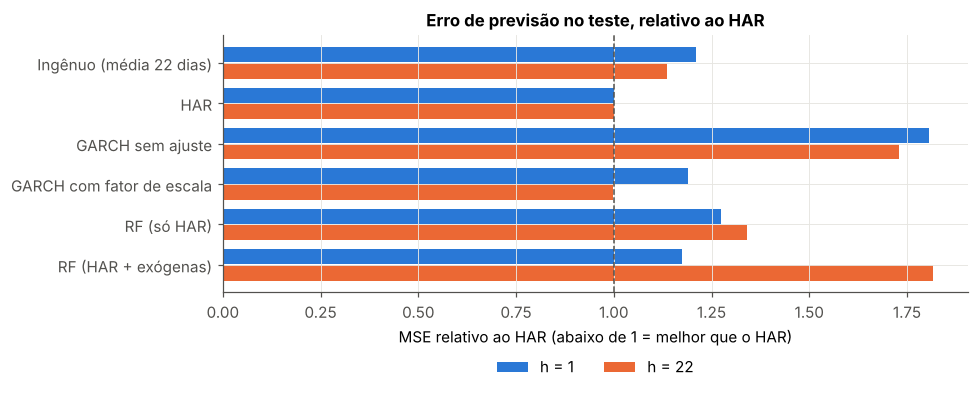

In [7]:
fig, ax = plt.subplots(figsize=(9, 3.8))
modelos_ord = list(avaliacoes[1].index)
y = np.arange(len(modelos_ord))
col = "MSE / MSE do HAR"
ax.barh(y - 0.2, avaliacoes[1].loc[modelos_ord, col], height=0.38, color=AZUL, label="h = 1")
ax.barh(y + 0.2, avaliacoes[22].loc[modelos_ord, col], height=0.38, color=LARANJA, label="h = 22")
ax.axvline(1, color=CINZA, lw=1, ls="--")
ax.set_yticks(y, modelos_ord)
ax.invert_yaxis()
ax.set_xlabel("MSE relativo ao HAR (abaixo de 1 = melhor que o HAR)")
ax.set_title("Erro de previsão no teste, relativo ao HAR")
ax.legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.2), ncol=2)
fig.tight_layout()
salvar(fig, "mod_01_mse_relativo")
plt.show()

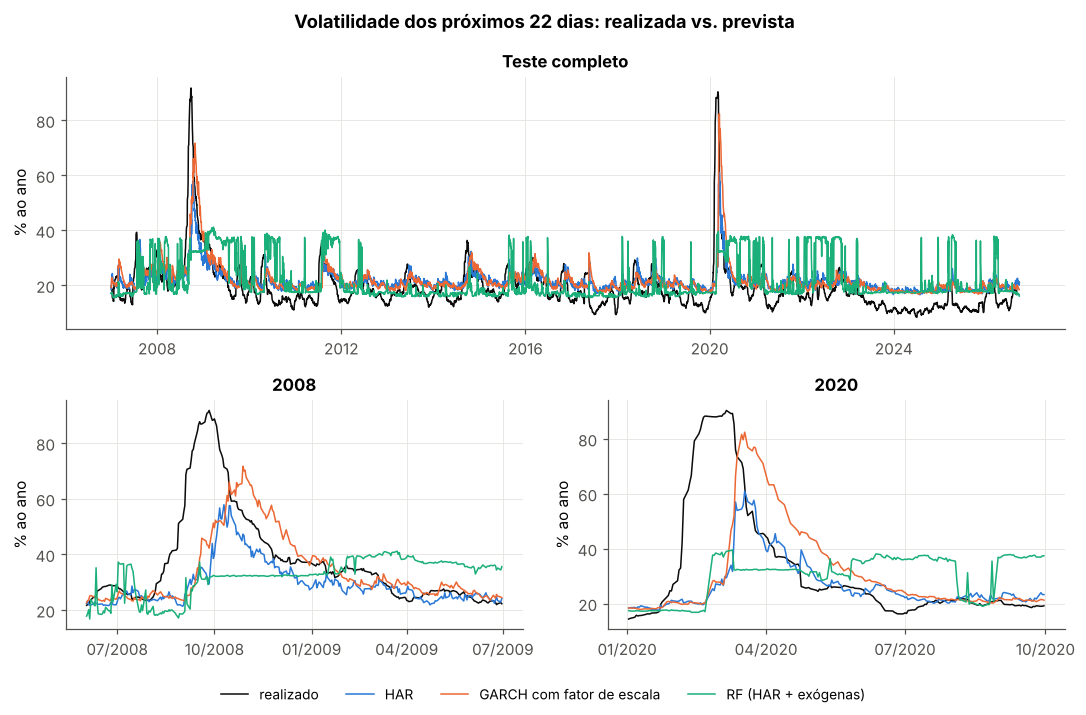

In [8]:
R = resultados[22]
p, real = R["previsoes"], R["realizado"]
series = [("HAR", AZUL), ("GARCH com fator de escala", LARANJA), ("RF (HAR + exógenas)", VERDE)]
janelas = [("Teste completo", None, None), ("2008", "2008-06-01", "2009-06-30"), ("2020", "2020-01-01", "2020-09-30")]

fig = plt.figure(figsize=(10, 6.5))
grade = fig.add_gridspec(2, 2, height_ratios=[1.1, 1])
eixos = [fig.add_subplot(grade[0, :]), fig.add_subplot(grade[1, 0]), fig.add_subplot(grade[1, 1])]
for ax, (titulo, ini, fim) in zip(eixos, janelas):
    s = slice(ini, fim)
    ax.plot(real.loc[s].index, real.loc[s], color="#0b0b0b", lw=1.0, label="realizado")
    for nome, cor in series:
        ax.plot(p.loc[s].index, p.loc[s, nome], color=cor, lw=1.0, label=nome)
    ax.set_title(titulo)
    ax.set_ylabel("% ao ano")
import matplotlib.dates as mdates
for ax in eixos[1:]:
    ax.xaxis.set_major_locator(mdates.MonthLocator(bymonth=[1, 4, 7, 10]))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%m/%Y"))
fig.suptitle("Volatilidade dos próximos 22 dias: realizada vs. prevista", fontweight="bold")
fig.tight_layout(rect=(0, 0.05, 1, 1))
alcas, rotulos = eixos[0].get_legend_handles_labels()
fig.legend(alcas, rotulos, frameon=False, ncol=4, loc="lower center", fontsize=9)
salvar(fig, "mod_02_previsoes_h22")
plt.show()

## 4. Diagnóstico

### 4.1 Erros em períodos de estresse e de calma

Esta é uma comparação descritiva, preparatória para a H3. O teste formal fica para a Etapa 3. Os períodos de estresse são os anos-calendário 2008, 2015–2016 e 2020.

In [9]:
linhas = {}
for h, R in resultados.items():
    e2 = R["previsoes"].sub(R["realizado"], axis=0) ** 2
    est = em_estresse(e2.index)
    linhas[(f"h = {h}", "estresse")] = e2[est].mean()
    linhas[(f"h = {h}", "calma")] = e2[~est].mean()
    linhas[(f"h = {h}", "só 2008 e 2020")] = e2.loc[(e2.index.year == 2008) | (e2.index.year == 2020)].mean()
tab_est = pd.DataFrame(linhas).T
tab_est.index.names = ["horizonte", "período"]
print("MSE por período")
tab_est.round(1)

MSE por período


Ingênuo (média 22 dias)    HAR  GARCH sem ajuste  \
horizonte período                                                            
h = 1     estresse                          213.0  157.3             236.2   
          calma                              53.9   49.4             101.3   
          só 2008 e 2020                    368.9  264.1             378.0   
h = 22    estresse                          224.1  159.5             204.1   
          calma                              24.1   30.8              71.5   
          só 2008 e 2020                    427.5  301.1             355.4   

                          GARCH com fator de escala  RF (só HAR)  \
horizonte período                                                  
h = 1     estresse                            176.1        245.3   
          calma                                61.4         51.5   
          só 2008 e 2020                      294.8        435.5   
h = 22    estresse                            163.0        213.1   
          calma                                29.7         41.4   
          só 2008 e 2020                      307.8        404.4   

                          RF (HAR + exógenas)  
horizonte período                              
h = 1     estresse                      208.5  
          calma                          51.9  
          só 2008 e 2020                361.7  
h = 22    estresse                      234.7  
          calma                          69.9  
          só 2008 e 2020                440.1

### 4.2 Por que o random forest foi mal: previsões fora da faixa do treino

Uma árvore de decisão só prevê médias de valores que **já viu no treino**. Por isso, o random forest não extrapola: se o teste traz situações fora da faixa do treino, a previsão fica presa nos extremos que ele conhece. As tabelas abaixo medem esse problema.

In [10]:
R = resultados[22]
tr, te = R["treino"], R["teste"]
faixa = pd.DataFrame({
    "treino: mín.": tr[M.HAR + M.EXOGENAS].min(),
    "treino: máx.": tr[M.HAR + M.EXOGENAS].max(),
    "teste: mín.": te[M.HAR + M.EXOGENAS].min(),
    "teste: máx.": te[M.HAR + M.EXOGENAS].max(),
    "% dos dias de teste fora da faixa do treino": 100 * ((te[M.HAR + M.EXOGENAS] < tr[M.HAR + M.EXOGENAS].min()) |
                                                          (te[M.HAR + M.EXOGENAS] > tr[M.HAR + M.EXOGENAS].max())).mean(),
})
display(faixa.round(3))

print("Alvo h=22, máximo no treino: %.1f | máximo no teste: %.1f" % (tr["alvo_h22"].max(), te["alvo_h22"].max()))
print("Maior previsão no teste -> HAR: %.1f | RF (só HAR): %.1f | RF (HAR + exógenas): %.1f" % (
    R["previsoes"]["HAR"].max(), R["previsoes"]["RF (só HAR)"].max(), R["previsoes"]["RF (HAR + exógenas)"].max()))

,treino: mín.,treino: máx.,teste: mín.,teste: máx.,% dos dias de teste fora da faixa do treino
har_d,4.716,122.198,1.904,186.528,0.737
har_s,9.160,64.638,6.090,126.738,3.725
har_m,13.714,48.330,8.351,91.771,24.253
retorno_log,-0.075,0.073,-0.160,0.137,0.450
log_vix,2.293,3.808,2.213,4.415,3.275
dolar_var_log,-0.094,0.048,-0.092,0.089,0.123
selic_meta,13.750,26.500,2.000,15.000,77.159
selic_var,-2.500,3.000,-1.500,1.500,0.000


Alvo h=22, máximo no treino: 48.3 | máximo no teste: 91.8
Maior previsão no teste -> HAR: 61.0 | RF (só HAR): 37.4 | RF (HAR + exógenas): 41.2


**Importância por permutação.** Para medir quanto o RF (HAR + exógenas) depende de cada variável no teste, embaralhamos uma variável de cada vez, o que destrói a informação dela, e medimos quanto o MSE aumenta. Um aumento grande indica que o modelo depende muito da variável. Um valor **negativo** indica que o modelo fica *melhor* sem ela no teste: a relação aprendida no treino atrapalha fora da amostra.

In [11]:
cols = M.HAR + M.EXOGENAS
imp = permutation_importance(R["rf_exo"], te[cols], R["realizado"], n_repeats=10, random_state=0,
                             scoring="neg_mean_squared_error", n_jobs=1)  # sem paralelismo: evita aviso do joblib no Windows
tab_imp = pd.DataFrame({"aumento do MSE (média)": imp.importances_mean, "desvio entre repetições": imp.importances_std},
                       index=cols).sort_values("aumento do MSE (média)", ascending=False)
tab_imp.round(2)

,aumento do MSE (média),desvio entre repetições
log_vix,51.86,1.89
har_s,1.65,0.23
har_d,0.26,0.02
dolar_var_log,0.08,0.02
retorno_log,0.03,0.01
selic_var,0.00,0.00
selic_meta,-0.04,0.02
har_m,-6.86,0.40


### 4.3 Resíduos do HAR

Se o HAR captasse toda a dinâmica da volatilidade, os erros de previsão de 1 dia não teriam padrão no tempo. O gráfico mostra a autocorrelação dos erros do HAR no teste com h = 1. Não analisamos h = 22 aqui: nesse horizonte, a sobreposição dos alvos já cria autocorrelação nos erros por construção.

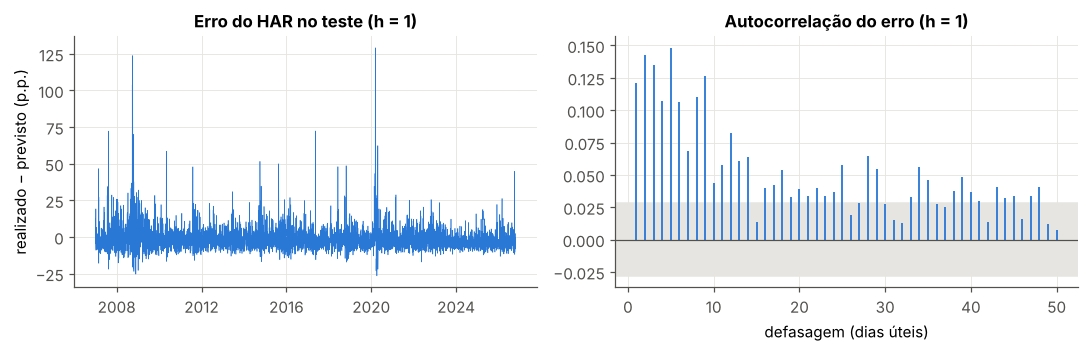

,lb_stat,lb_pvalue
5,425.2587,0.0
22,797.5827,0.0


Erro médio do HAR no teste (h=1): -1.07 p.p. | assimetria do erro: 4.05


In [12]:
R1 = resultados[1]
erro_har = (R1["realizado"] - R1["previsoes"]["HAR"]).dropna()
a = acf(erro_har, nlags=50)
fig, axs = plt.subplots(1, 2, figsize=(10, 3.3))
axs[0].plot(erro_har.index, erro_har, color=AZUL, lw=0.4)
axs[0].set_title("Erro do HAR no teste (h = 1)")
axs[0].set_ylabel("realizado − previsto (p.p.)")
axs[1].vlines(range(1, 51), 0, a[1:], color=AZUL)
axs[1].axhspan(-1.96 / np.sqrt(len(erro_har)), 1.96 / np.sqrt(len(erro_har)), color=SOMBRA, zorder=0)
axs[1].axhline(0, color=CINZA, lw=0.8)
axs[1].set_title("Autocorrelação do erro (h = 1)")
axs[1].set_xlabel("defasagem (dias úteis)")
fig.tight_layout()
salvar(fig, "mod_03_residuos_har")
plt.show()

display(acorr_ljungbox(erro_har, lags=[5, 22], return_df=True).round(4))
print(f"Erro médio do HAR no teste (h=1): {erro_har.mean():.2f} p.p. | assimetria do erro: {erro_har.skew():.2f}")

### 4.4 A métrica de erro muda a conclusão? (Patton, 2011)

A volatilidade verdadeira não é observável. O alvo deste trabalho é uma **estimativa** dela (Garman-Klass), e toda estimativa tem ruído. Patton (2011) mostra que, nessa situação, só algumas funções de perda garantem que o modelo com menor erro medido seja também o melhor diante da volatilidade verdadeira. O MSE calculado sobre a **variância** e a perda **QLIKE** são robustas. O MSE calculado sobre a **volatilidade** (a raiz), usado na seção 3, **não é**.

Por isso, a tabela abaixo recalcula a comparação com as duas perdas robustas. Valores menores que 1 indicam erro menor que o do HAR, e as colunas de posição ordenam os modelos (1 = menor erro).

In [13]:
for h, R in resultados.items():
    print(f"\nHorizonte h = {h} dia(s)")
    display(M.perdas_robustas(R["previsoes"], R["realizado"]).round(3))


Horizonte h = 1 dia(s)


,MSE na volatilidade / HAR,MSE na variância / HAR,QLIKE / HAR,posição (MSE vol.),posição (MSE var.),posição (QLIKE)
Ingênuo (média 22 dias),1.209,1.175,1.105,4,4,3
HAR,1.000,1.000,1.000,1,1,1
GARCH sem ajuste,1.806,1.105,1.493,6,3,6
GARCH com fator de escala,1.189,1.005,1.132,3,2,4
RF (só HAR),1.274,1.307,1.151,5,6,5
RF (HAR + exógenas),1.174,1.210,1.058,2,5,2



Horizonte h = 22 dia(s)


,MSE na volatilidade / HAR,MSE na variância / HAR,QLIKE / HAR,posição (MSE vol.),posição (MSE var.),posição (QLIKE)
Ingênuo (média 22 dias),1.136,1.467,1.073,3,6,3
HAR,1.000,1.000,1.000,2,1,2
GARCH sem ajuste,1.729,1.371,1.457,5,4,5
GARCH com fator de escala,0.997,1.016,0.960,1,2,1
RF (só HAR),1.340,1.229,1.285,4,3,4
RF (HAR + exógenas),1.815,1.448,1.464,6,5,6


## 5. Síntese (rascunho — conferir com as tabelas acima)

**Resultados**

1. **h = 1:** o HAR tem o menor erro (MSE 71,2). Todos os outros erram de 17% a 27% mais, e o GARCH sem fator de escala, 81% mais.
2. **h = 22:** o HAR e o GARCH com fator de escala praticamente empatam (MSE 56,9 contra 56,8). Sem o teste de Diebold-Mariano (Etapa 3), não é possível dizer qual é melhor. Os dois superam a referência ingênua. O RF (HAR + exógenas) tem o **maior** erro de todos (1,82 vez o do HAR).

**Leitura preliminar das hipóteses**

3. **H1 (HAR supera o GARCH):** apoiada em h = 1 e inconclusiva em h = 22.
4. **H2 (ML com exógenas supera os dois, sobretudo em h = 22):** **não apoiada** nesta versão. As exógenas melhoram o RF em h = 1 (MSE 83,6 contra 90,7 do RF só com HAR), mas pioram muito em h = 22 (103,4 contra 76,3). Mesmo assim, nenhum RF supera o HAR.
5. **H3 (ganho do ML concentrado no estresse):** **não apoiada** nesta versão. Nos períodos de estresse, o HAR tem o menor erro nos dois horizontes.

**Diagnóstico: por que o RF foi mal**

6. O RF não extrapola, e o treino de 2000–2006 não contém os extremos do teste. A maior previsão do RF em h = 22 é 41% a.a., enquanto o realizado chega a 92% (em 2008 e 2020). Além disso, a média de 22 dias fica fora da faixa do treino em 24% dos dias do teste, e a Selic, em 77%.
7. O RF (HAR + exógenas) depende quase só do VIX: embaralhar o VIX aumenta o MSE em cerca de 52. Já a média de 22 dias tem importância **negativa** no teste, ou seja, a relação aprendida no treino atrapalha fora dele. No gráfico de previsões, isso aparece como saltos bruscos e episódicos do RF para patamares de 35–40% a.a. em fases calmas (por exemplo, em 2024–2025), enquanto a volatilidade realizada segue baixa. É o comportamento esperado de um modelo que reage a um único indicador externo.

**Diagnóstico: limitações comuns a todos os modelos**

8. Todos os modelos preveem, em média, volatilidade alta demais no teste (viés de +0,7 a +3,3 p.p., sem contar o GARCH sem fator), porque o treino foi um período mais volátil. A média de longo prazo implícita no HAR de h = 22 é 23,8% a.a. Em fases calmas, isso faz o HAR (h = 22) perder até para a referência ingênua.
9. Os erros do HAR em h = 1 são autocorrelacionados (o Ljung-Box rejeita a hipótese de erros sem padrão). Com parâmetros fixos desde 2006, o modelo não acompanha as mudanças de nível da volatilidade.
10. O fator de escala é essencial para comparar o GARCH: sem ele, o MSE sobe 52% (h = 1) e 73% (h = 22).
11. **Robustez da métrica (seção 4.4).** Com as perdas robustas de Patton (2011), o HAR continua sendo o melhor em h = 1 e nenhum RF supera o HAR em nenhum horizonte. Em h = 22, a ordem entre HAR e GARCH com fator depende da perda: o HAR vence no MSE da variância, e o GARCH vence na QLIKE. Isso reforça que a H1 é inconclusiva nesse horizonte.

**Ajustes sugeridos para a Etapa 3** (a decidir lá)

- A janela expansiva deve reduzir os problemas 6, 8 e 9, porque o treino passa a incluir 2008 e os anos seguintes.
- Adotar a QLIKE e o MSE na variância como perdas principais (Patton, 2011), mantendo o MSE na volatilidade como complementar.
- Rever o uso da Selic em nível no RF: no treino ela só assume valores que quase não se repetem no teste.
- Verificar se outro desenho do RF reduz o problema de extrapolação, sempre definido antes de olhar o teste. Uma opção é prever a diferença entre o alvo e o HAR, em vez do nível.